# Star catalogue for the Moonwalk project

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib notebook

In [4]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# from astropy.table import Table
# from astropy.time import Time
from astropy import units as u
from astropy import constants as c
from astropy.coordinates import SkyCoord
from tqdm import tqdm
from pathlib import Path
# from mpl_toolkits.axes_grid1 import make_axes_locatable
# from ipywidgets import *

# PlatoSim libraries
# import platosim.smbhb     as bh
# import platosim.slurm     as sm
import platosim.utilities as ut
import platosim.plot      as pt
# import platosim.noise     as ns
# import platosim.starquery as sq
# from platosim.lightcurve   import LightCurve
# from platosim.slurm        import workerOverview
from platosim.matplotlibrc import setup_notebook
setup_notebook()

from IPython.display import display, HTML
display(HTML("<style>.container {width:70% !important; }</style>"))

In [82]:
# Paths to where data is stored
hdir = ut.getHomeDir('inputfiles/data_picsim')
path = ut.getWorkDir('moonwalk')
idir = path / 'input'
fdir = path / 'figures'
# ddir = path / 'data'
# sdir = path / 'simulations'
fdir = Path('/lhome/nicholas/Nextcloud/latex/papers/2027_Moonwalk/figures')

In [6]:
# Load PIC LOSP2 catalogue
dc = pd.read_feather(hdir / 'PlatoGO_PIC210_LOPS2.ftr')

In [133]:
dt = pd.read_feather(idir / 'starcat_PIC220_Prime_LOPS2_targets.ftr')
# df = pd.read_feather(idir / 'starcat_PIC220_P1_LOPS2_targets.ftr')
dt = dt.sort_values(by='Pmag', ascending=False)
dt = dt[(dt.Pmag > 7.5) & (dt.Pmag < 11)]
dt.head()

,ID,PIC,gaiaDR3,l,b,ra,dec,pmra,pmdec,Pmag,...,Teff,logg,ncams,case,source,tPIC,fgPIC,cPIC,scvPIC,ncon
4532,000004533,2671114000665,b'Gaia DR3 5523181918078370944',262.904824,-2.192299,128.960859,-44.302291,-17.992010,88.365834,10.999803,...,5605.733769,4.494226,6,1,5,36,0,0,0,4.0
5875,000005876,2547051000029,b'Gaia DR3 4844453871274839168',241.101732,-46.364830,63.691057,-38.312390,4.780559,-54.069475,10.999784,...,5566.415650,4.565394,6,1,21,36,0,576,0,0.0
1971,000001972,2874381000008,b'Gaia DR3 4731229531100608256',267.474796,-46.904770,57.874023,-55.920028,200.018987,81.563018,10.999738,...,4055.816285,4.521653,6,1,5,36,0,0,0,0.0
806,000000807,2974929000110,b'Gaia DR3 5477350077234549376',272.630284,-26.859941,96.408773,-63.064579,-4.314372,-1.630212,10.999608,...,6003.184082,4.403658,12,1,5,36,0,0,0,0.0
6414,000006415,2491940000109,b'Gaia DR3 5581448062878674560',243.519257,-20.577858,96.095344,-35.749690,-7.187581,27.566680,10.999506,...,5336.146223,4.509452,12,1,5,36,0,0,0,1.0


In [135]:
# Seperate into spectral classes
dK = dt[dt.Teff < 5300]
dG = dt[(dt.Teff > 5300) & (dt.Teff < 5900)]
dF = dt[dt.Teff > 5900]

## Plot targets in LOPS2 footprint

<IPython.core.display.Javascript object>


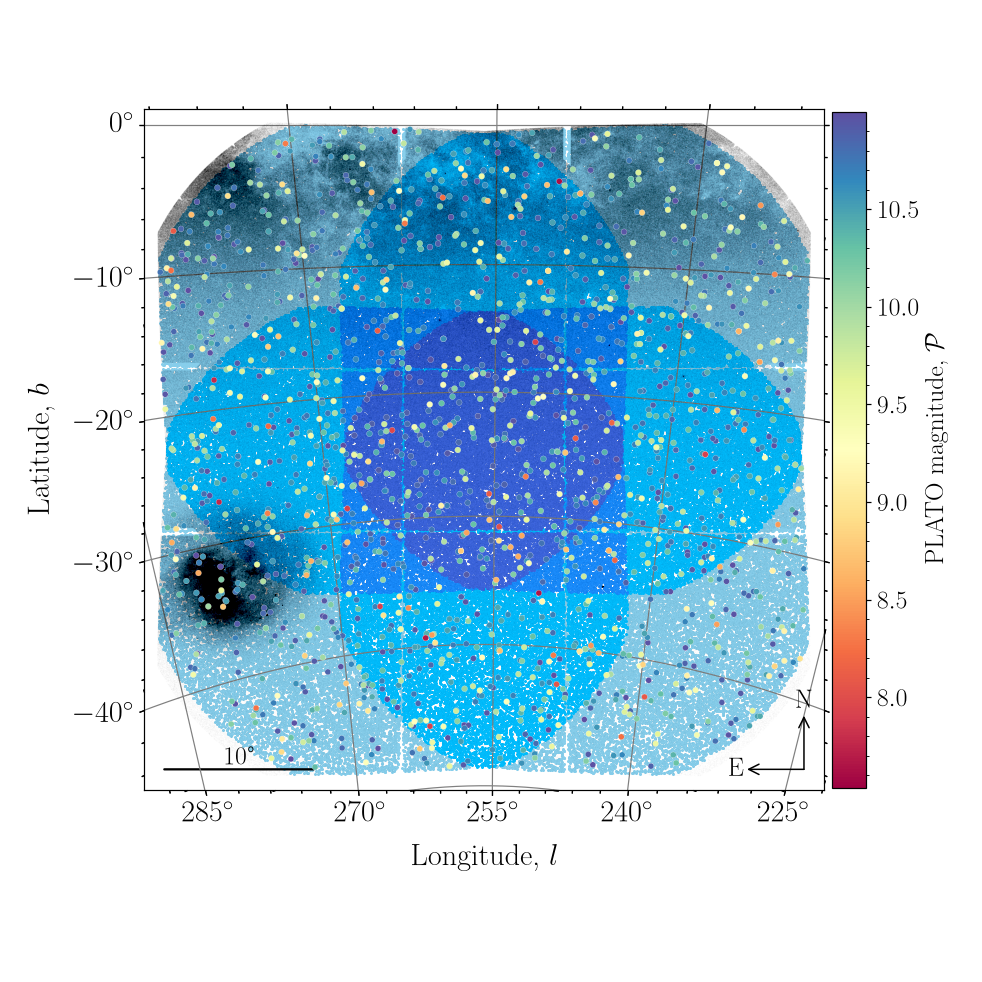

In [173]:
# Plot catalogue within LOPS2 foorptint
dx = dK
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=True, showGalactic=True,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cbarExtend=None, s=60, lw=0.15, ec='w', fovSize=27.5,
    clabel=r'PLATO magnitude, $\mathcal{P}$', cmap='Spectral', figsize=(9,9)
)
fig.savefig(fdir / 'starcat_footprint.png', bbox_inches='tight', dpi=200)

## Plot parameter space

In [80]:
# fig2, ax = pt.plotTeffvsRadius(ds, dK, dG, dF, sg, sgK, sgG, sgF, df,
dt.columns

Index(['ID', 'PIC', 'gaiaDR3', 'l', 'b', 'ra', 'dec', 'pmra', 'pmdec', 'Pmag',
       'PBmag', 'PRmag', 'M', 'R', 'Teff', 'logg', 'ncams', 'case', 'source',
       'tPIC', 'fgPIC', 'cPIC', 'scvPIC', 'ncon'],
      dtype='str')

<IPython.core.display.Javascript object>


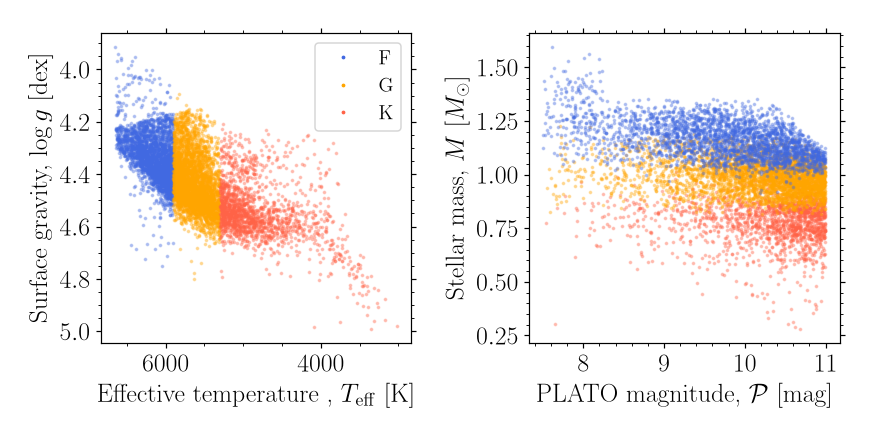

In [172]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
aa, ms = 0.3, 3
cc = ['tomato', 'orange', 'royalblue']

# Plot Teff vs. logg
ax[0].plot(dF.Teff, dF.logg, '.', ms=ms, alpha=aa, label='F', c=cc[2])
ax[0].plot(dG.Teff, dG.logg, '.', ms=ms, alpha=aa, label='G', c=cc[1])
ax[0].plot(dK.Teff, dK.logg, '.', ms=ms, alpha=aa, label='K', c=cc[0])
ax[0].set_xlabel(r'Effective temperature , $T_{\rm eff}$ [K]')
ax[0].set_ylabel(r'Surface gravity, $\log g$ [dex]')
ax[0].xaxis.set_inverted(True)
ax[0].yaxis.set_inverted(True)
leg = ax[0].legend(loc='upper right', fontsize=13)
pt.makeLegendMarkersOpaque(leg)
        
# Plot Pmag vs. M
ax[1].plot(dK.Pmag, dK.M, '.', ms=ms, alpha=aa, c=cc[0])
ax[1].plot(dG.Pmag, dG.M, '.', ms=ms, alpha=aa, c=cc[1])
ax[1].plot(dF.Pmag, dF.M, '.', ms=ms, alpha=aa, c=cc[2])
ax[1].set_xlabel(r'PLATO magnitude, $\mathcal{P}$ [mag]')
ax[1].set_ylabel(r'Stellar mass, $M$ [$M_{\odot}$]')

plt.tight_layout()
fig.savefig(fdir / 'starcat_stellar_parameters.png', bbox_inches='tight', dpi=200)